# EDA: complaint failure analysis and complaint ↔ recall relationships

This notebook only **reads** data through the pipeline's loader (same cleaning and component harmonisation as
the models). It does not change the pipeline.

Save it in the project's top folder (next to `README.md` and `recall_pipeline/`), choose your Python
environment as the kernel, and run the cells top to bottom.

1. Setup and loading
2. Failure analysis (complaints)
3. Recall characteristics
4. Complaints ↔ recalls: how do they relate?

In [1]:
# ---- settings: edit these ----------------------------------------------------------
COMPLAINTS = "data/complaints.csv"
RECALLS    = "data/recalls.csv"
MIN_DATE   = "2008-01-01"   # skip complaints received before this (None = keep all)
MAX_ROWS   = None           # e.g. 300_000 for a quick first look; None = all rows (uses the pipeline's cache)
HORIZON_DAYS = 730          # "recall within N days" used in section 4
TOP_N = 12                  # how many components / makes to show in rankings

In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr

# Make `import recall_pipeline` work when the notebook sits in the project folder (or a subfolder of it)
for p in [Path.cwd(), *Path.cwd().parents]:
    if (p / "recall_pipeline").is_dir():
        sys.path.insert(0, str(p)); break

# ---- chart style: one consistent, colour-blind-checked palette ----------------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, RED = PALETTE[0], PALETTE[1], PALETTE[7]
TEXT, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
SEQ = LinearSegmentedColormap.from_list(
    "blue_seq", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110, "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": TEXT, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2,
})

def finish(ax, title, xlabel=None, ylabel=None, subtitle=None):
    ax.set_title(title + (f"\n{subtitle}" if subtitle else ""), loc="left")
    if xlabel is not None: ax.set_xlabel(xlabel)
    if ylabel is not None: ax.set_ylabel(ylabel)
    plt.tight_layout(); plt.show()

def hbar(series, title, xlabel, color=BLUE, fmt="{:,.0f}", subtitle=None):
    s = series.sort_values()
    fig, ax = plt.subplots(figsize=(10, 0.32 * len(s) + 1.2))
    ax.barh(s.index.astype(str), s.values, color=color, height=0.7)
    ax.grid(axis="y", visible=False)
    for i, v in enumerate(s.values):                       # value labels at bar ends (few bars only)
        ax.text(v, i, " " + fmt.format(v), va="center", color=MUTED, fontsize=9)
    finish(ax, title, xlabel, subtitle=subtitle)

In [3]:
from recall_pipeline.config import Config
from recall_pipeline.data_io import load_complaints, load_recalls
from recall_pipeline.components import add_component

cfg = Config(complaints_path=COMPLAINTS, recalls_path=RECALLS, complaints_min_date=MIN_DATE,
             debug_max_rows=MAX_ROWS, horizon_days=HORIZON_DAYS)
c, r = add_component(load_complaints(cfg), load_recalls(cfg), cfg.component_level)

# convenience columns (notebook only)
for col in ["CRASH", "FIRE", "POLICE_RPT_YN"]:
    c[col + "_flag"] = c[col].eq("Y").fillna(False).astype(int)
c["injury_flag"] = (c["INJURED"].fillna(0) > 0).astype(int)
c["death_flag"]  = (c["DEATHS"].fillna(0) > 0).astype(int)
c["vehicle_age"] = (c["DATEA"].dt.year - c["YEARTXT"].astype(float)).clip(-1, 40)
from recall_pipeline.labeling import make_key                       # same matching key as the models
KEYS = ["MAKETXT", "MODELTXT", "YEARTXT", "COMPONENT"]
c["MMYC"], r["MMYC"] = make_key(c, KEYS), make_key(r, KEYS)
campaigns = r.drop_duplicates("CAMPNO")            # one row per recall campaign

pd.DataFrame({
    "rows": [len(c), len(r), len(campaigns)],
    "from": [c.DATEA.min().date(), r.RCDATE.min().date(), campaigns.RCDATE.min().date()],
    "to":   [c.DATEA.max().date(), r.RCDATE.max().date(), campaigns.RCDATE.max().date()],
}, index=["complaints (complaint × component rows)", "recall rows (campaign × vehicle × component)", "recall campaigns"])

  complaints: read 2,400,000 rows, kept 1,568,185


,rows,from,to
complaints (complaint × component rows),1561746,2008-01-01,2026-09-27
recall rows (campaign × vehicle × component),218435,2010-01-01,2026-09-24
recall campaigns,13525,2010-01-01,2026-09-24


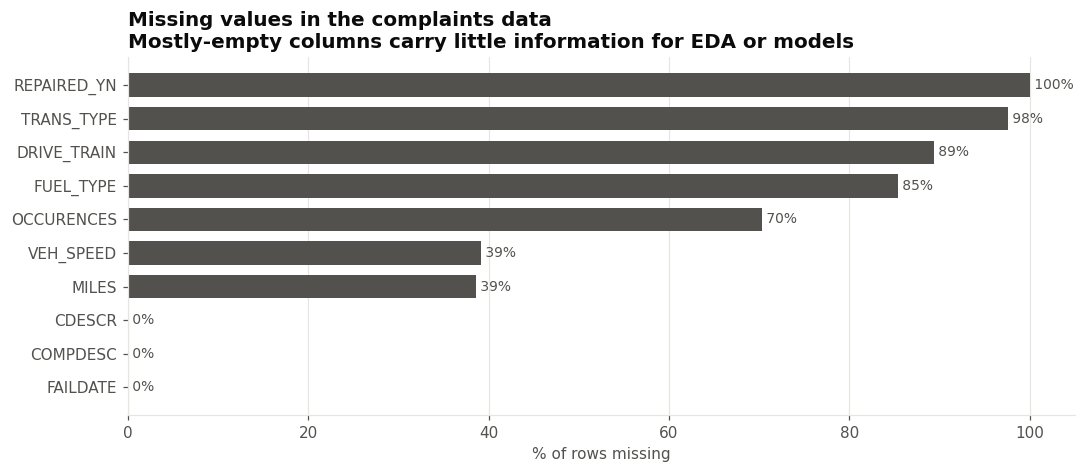

In [4]:
miss = (100 * c.drop(columns=["MMYC"]).isna().mean()).sort_values(ascending=False)
hbar(miss[miss > 0].head(15), "Missing values in the complaints data", "% of rows missing",
     color=MUTED, fmt="{:.0f}%", subtitle="Mostly-empty columns carry little information for EDA or models")

---
## 2. Failure analysis (complaints)
What fails, on which vehicles, how seriously, and when.

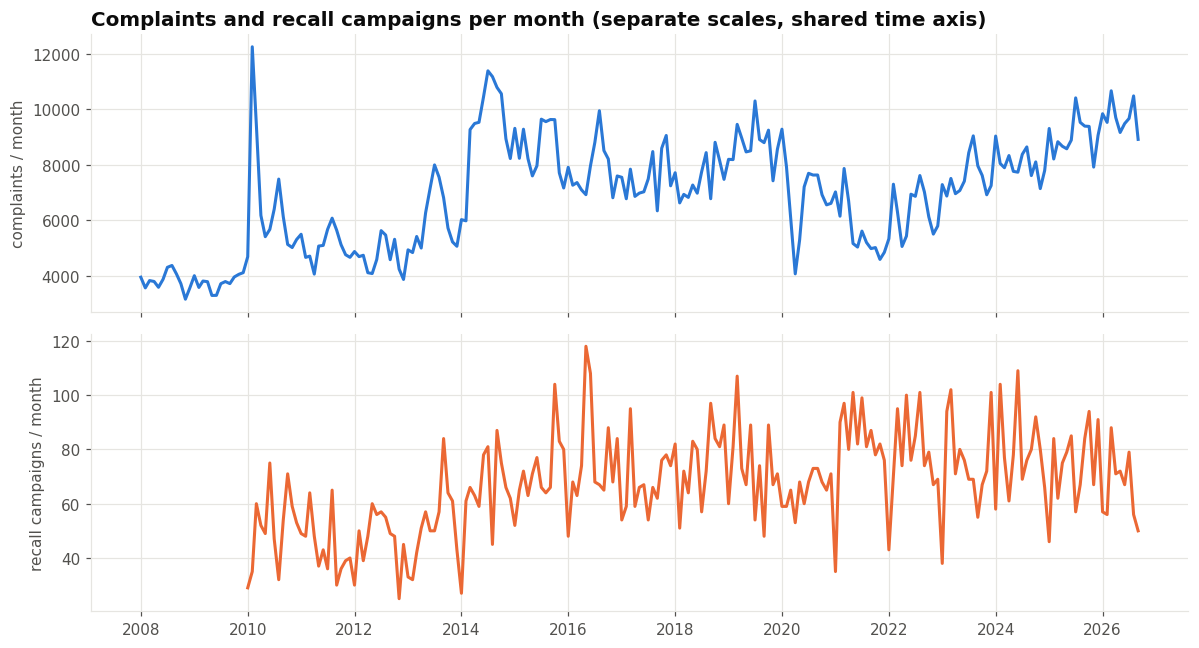

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
m_c = c.set_index("DATEA").resample("MS").size()
m_r = campaigns.set_index("RCDATE").resample("MS").size()
axes[0].plot(m_c.index, m_c.values, color=BLUE);   axes[0].set_ylabel("complaints / month")
axes[1].plot(m_r.index, m_r.values, color=ORANGE); axes[1].set_ylabel("recall campaigns / month")
axes[0].set_title("Complaints and recall campaigns per month (separate scales, shared time axis)", loc="left")
plt.tight_layout(); plt.show()

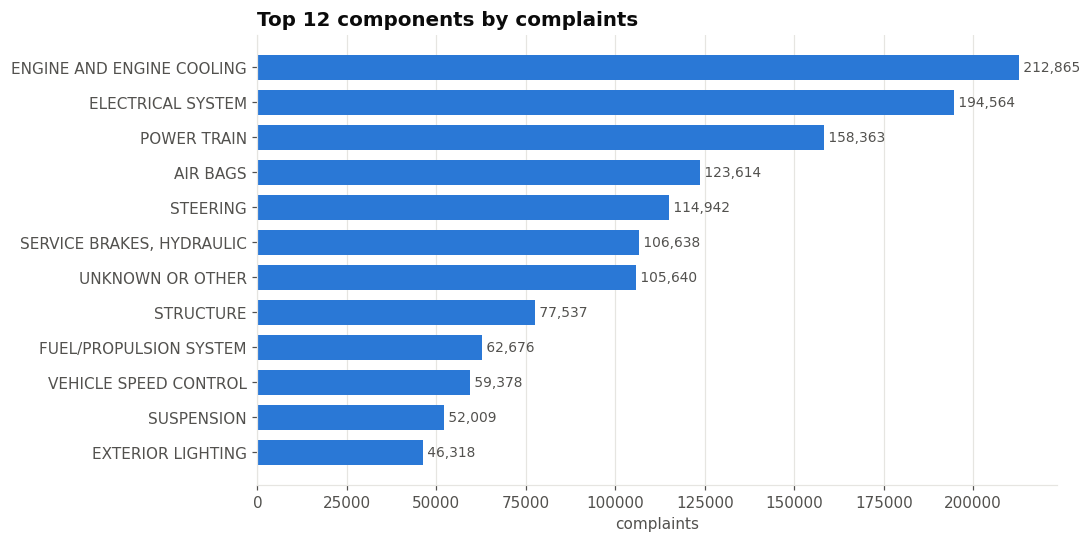

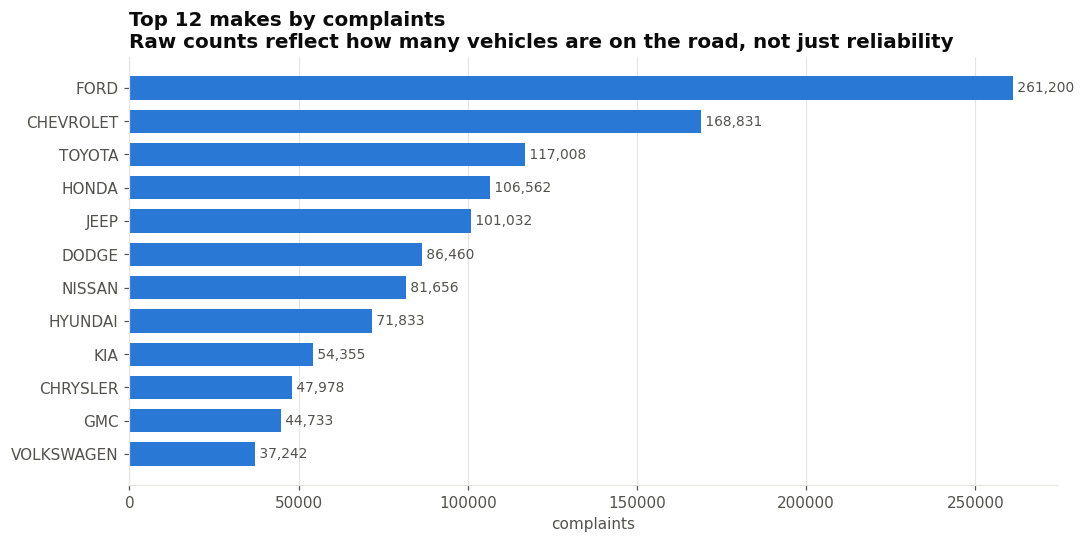

In [6]:
hbar(c["COMPONENT"].value_counts().head(TOP_N), f"Top {TOP_N} components by complaints", "complaints")
hbar(c["MAKETXT"].value_counts().head(TOP_N), f"Top {TOP_N} makes by complaints", "complaints",
     subtitle="Raw counts reflect how many vehicles are on the road, not just reliability")

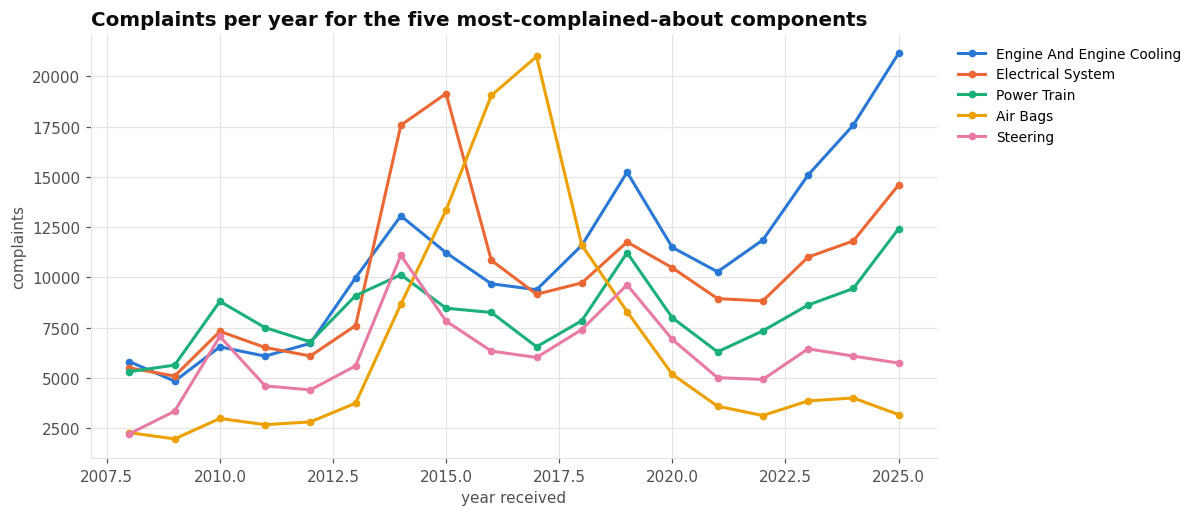

In [7]:
top_comp = c["COMPONENT"].value_counts().head(5).index
yearly = (c[c["COMPONENT"].isin(top_comp)].assign(year=c["DATEA"].dt.year)
          .groupby(["year", "COMPONENT"]).size().unstack(fill_value=0))
yearly = yearly.iloc[:-1] if c["DATEA"].max().month < 12 else yearly   # drop a partial last year
fig, ax = plt.subplots(figsize=(11, 4.8))
for i, comp in enumerate(top_comp):
    ax.plot(yearly.index, yearly[comp], color=PALETTE[i], label=comp.title(), marker="o", markersize=4)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
finish(ax, "Complaints per year for the five most-complained-about components", "year received", "complaints")

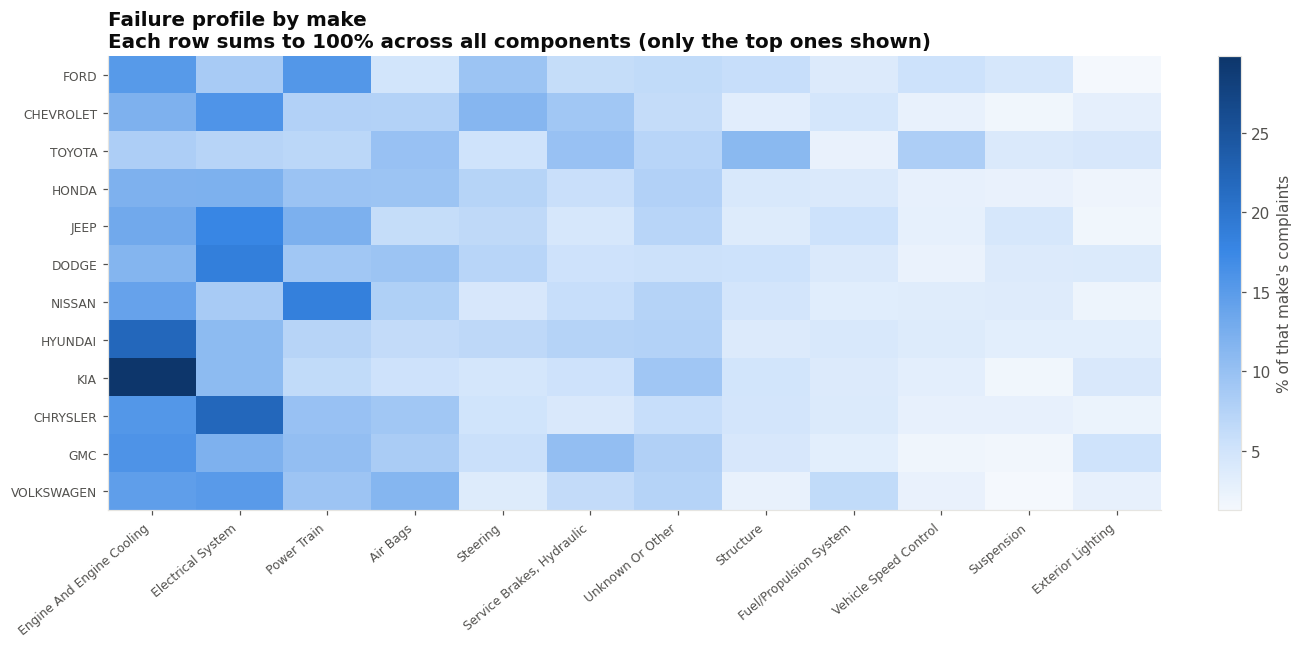

In [8]:
top_makes = c["MAKETXT"].value_counts().head(TOP_N).index
top_comps = c["COMPONENT"].value_counts().head(TOP_N).index
mix = (pd.crosstab(c["MAKETXT"], c["COMPONENT"], normalize="index").loc[top_makes, top_comps] * 100)
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(mix.values, cmap=SEQ, aspect="auto")
ax.set_xticks(range(len(top_comps)), [s.title() for s in top_comps], rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(len(top_makes)), top_makes, fontsize=8)
ax.grid(False)
cb = plt.colorbar(im, ax=ax, fraction=0.03); cb.set_label("% of that make's complaints", color=MUTED)
finish(ax, "Failure profile by make", subtitle="Each row sums to 100% across all components (only the top ones shown)")

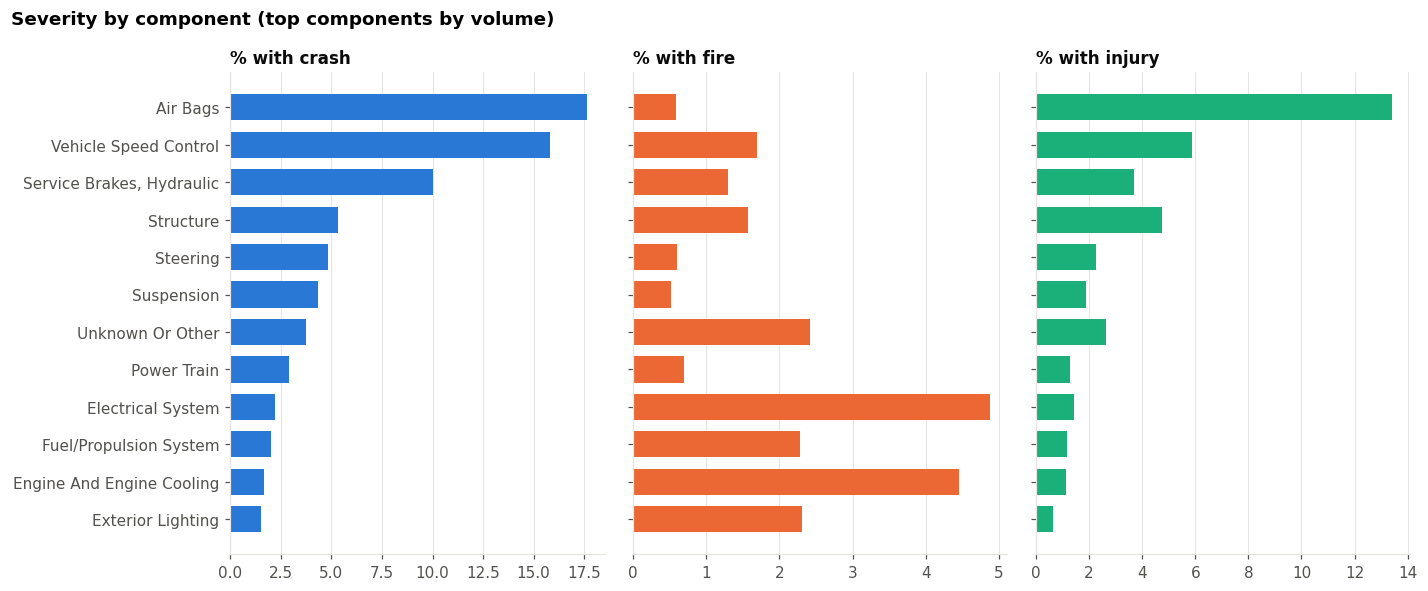

In [9]:
sev = (c.groupby("COMPONENT")[["CRASH_flag", "FIRE_flag", "injury_flag"]].mean() * 100)
sev = sev.loc[c["COMPONENT"].value_counts().head(TOP_N).index]
fig, axes = plt.subplots(1, 3, figsize=(13, 0.32 * TOP_N + 1.6), sharey=True)
for ax, col, label, color in zip(axes, sev.columns, ["crash", "fire", "injury"], [BLUE, ORANGE, PALETTE[2]]):
    s = sev[col].sort_values() if ax is axes[0] else sev[col].reindex(sev["CRASH_flag"].sort_values().index)
    ax.barh(s.index.str.title(), s.values, color=color, height=0.7)
    ax.set_title(f"% with {label}", loc="left", fontsize=11); ax.grid(axis="y", visible=False)
fig.suptitle("Severity by component (top components by volume)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

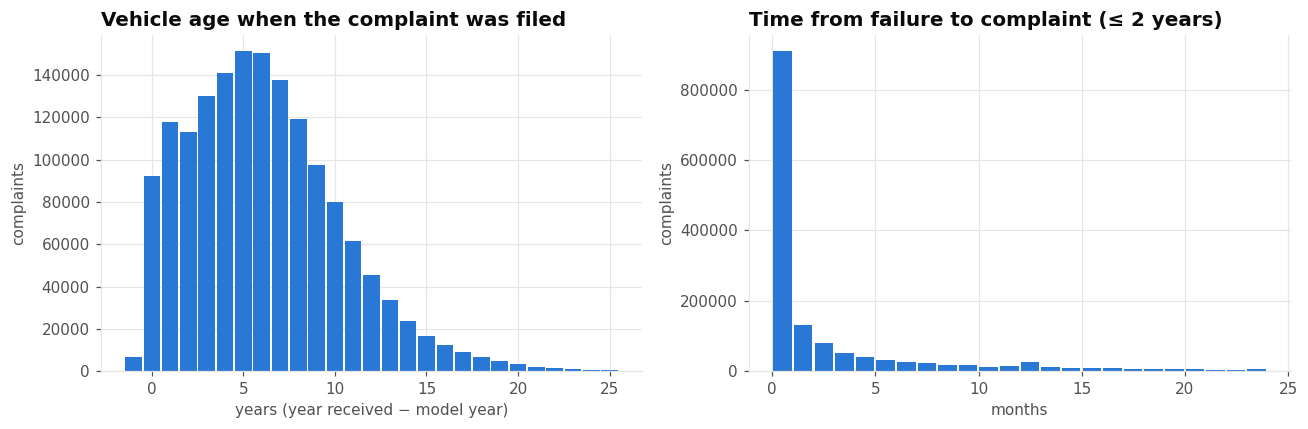

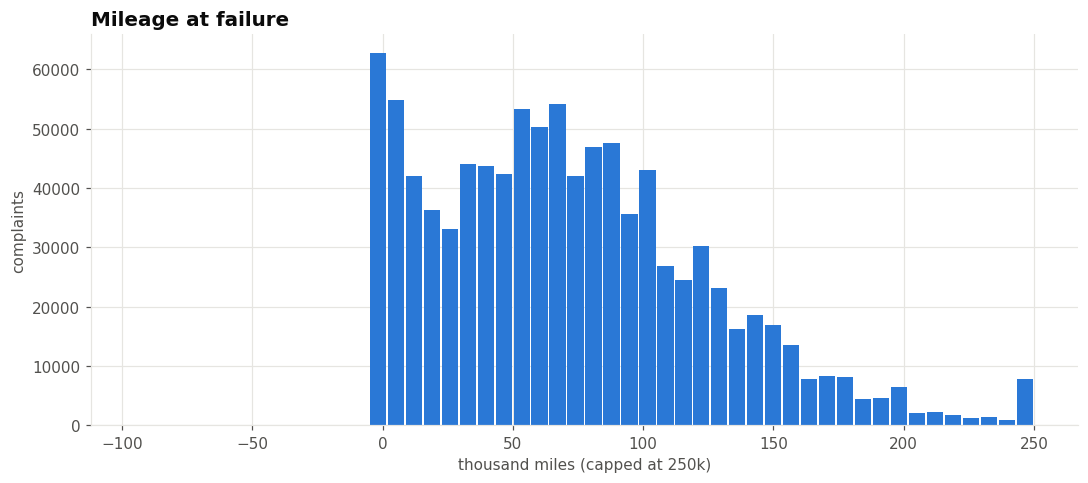

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(c["vehicle_age"].dropna(), bins=np.arange(-1.5, 26.5, 1), color=BLUE, rwidth=0.9)
axes[0].set_title("Vehicle age when the complaint was filed", loc="left"); axes[0].set_xlabel("years (year received − model year)")
gap = (c["DATEA"] - c["FAILDATE"]).dt.days if "FAILDATE" in c else pd.Series(dtype=float)
gap = gap[(gap >= 0) & (gap <= 730)]
if len(gap):
    axes[1].hist(gap / 30.44, bins=24, color=BLUE, rwidth=0.9)
else:
    axes[1].text(0.5, 0.5, "No usable FAILDATE values", ha="center", transform=axes[1].transAxes, color=MUTED)
axes[1].set_title("Time from failure to complaint (≤ 2 years)", loc="left"); axes[1].set_xlabel("months")
for ax in axes: ax.set_ylabel("complaints")
plt.tight_layout(); plt.show()
if c["MILES"].notna().mean() > 0.01:
    fig, ax = plt.subplots()
    ax.hist(c["MILES"].dropna().clip(upper=250_000) / 1000, bins=50, color=BLUE, rwidth=0.9)
    finish(ax, "Mileage at failure", "thousand miles (capped at 250k)", "complaints")
else:
    print(f"MILES is filled in for only {100 * c['MILES'].notna().mean():.2f}% of rows - skipped.")

In [11]:
# What do people actually describe? Most distinctive terms per component (TF-IDF on a sample).
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
domain_stop = {"vehicle", "car", "contact", "owns", "stated", "manufacturer", "dealer", "dealership", "approximate",
               "failure", "mileage", "notified", "issue", "problem", "tl", "ia", "consumer", "said", "told"}
stop = (ENGLISH_STOP_WORDS - {"not", "no", "never"}) | domain_stop      # keep negations: "did not deploy"
sample = c.sample(min(len(c), 60_000), random_state=0)
tf = TfidfVectorizer(stop_words=list(stop), ngram_range=(1, 2), min_df=20, max_features=20_000, sublinear_tf=True)
X = tf.fit_transform(sample["CDESCR"].fillna("").astype(str))
terms = np.array(tf.get_feature_names_out())
overall = np.asarray(X.mean(axis=0)).ravel()
rows = {}
for comp in sample["COMPONENT"].value_counts().head(8).index:
    m = (sample["COMPONENT"] == comp).values
    lift = np.asarray(X[m].mean(axis=0)).ravel() - overall              # over-represented vs all complaints
    rows[comp.title()] = ", ".join(terms[np.argsort(-lift)[:8]])
pd.Series(rows, name="most distinctive terms").to_frame()

,most distinctive terms
Engine And Engine Cooling,"engine, oil, coolant, check engine, check, eng..."
Electrical System,"electrical, battery, start, ignition, key, lig..."
Power Train,"transmission, gear, shift, shifting, gears, tr..."
Air Bags,"air, bags, air bags, airbag, bag, air bag, rec..."
Steering,"steering, power steering, power, wheel, steeri..."
"Service Brakes, Hydraulic","brake, brakes, abs, brake pedal, pedal, brakin..."
Unknown Or Other,"sunroof, door, glass, cracked, dashboard, open..."
Structure,"door, frame, open, rust, rusted, paint, rear, ..."


---
## 3. Recall characteristics

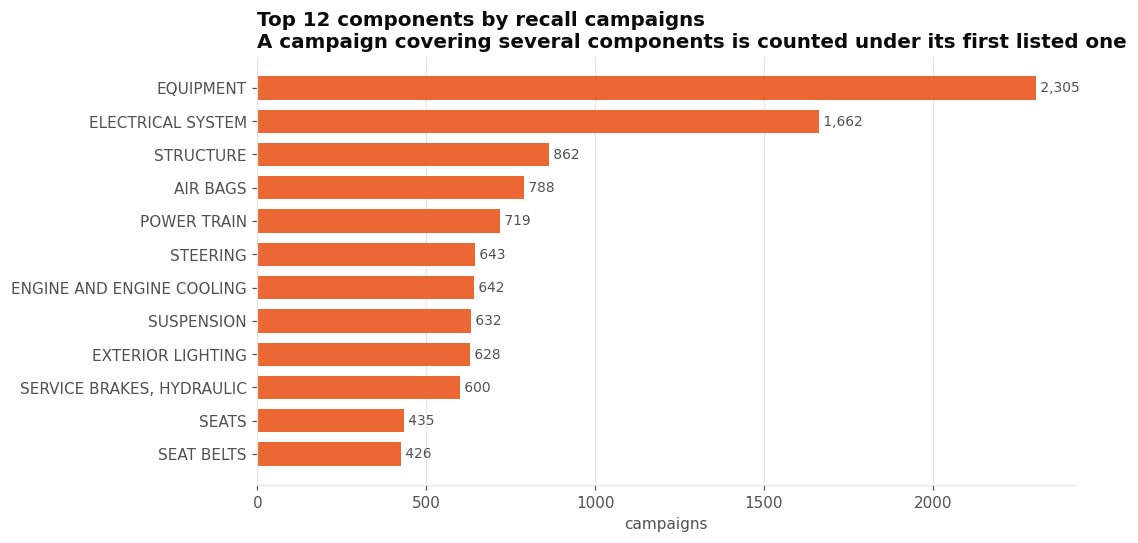

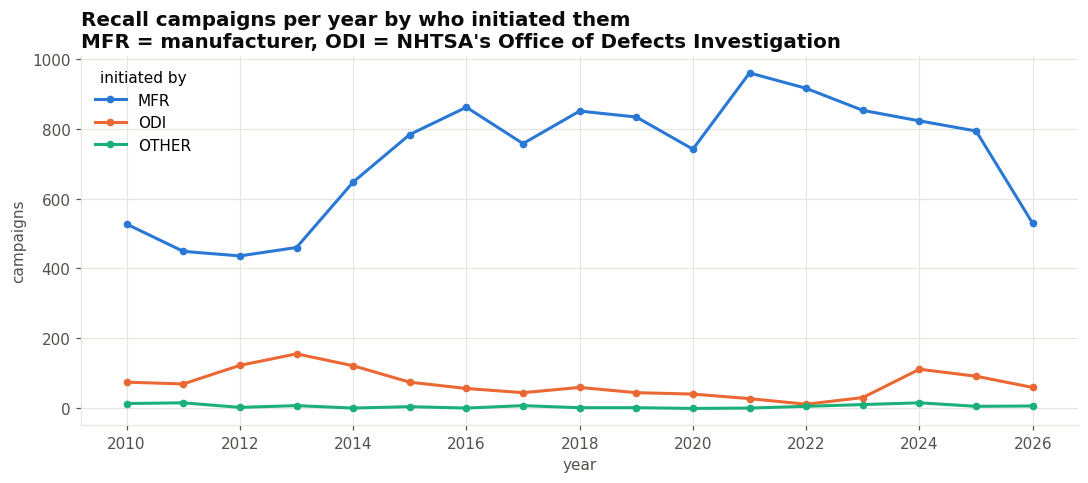

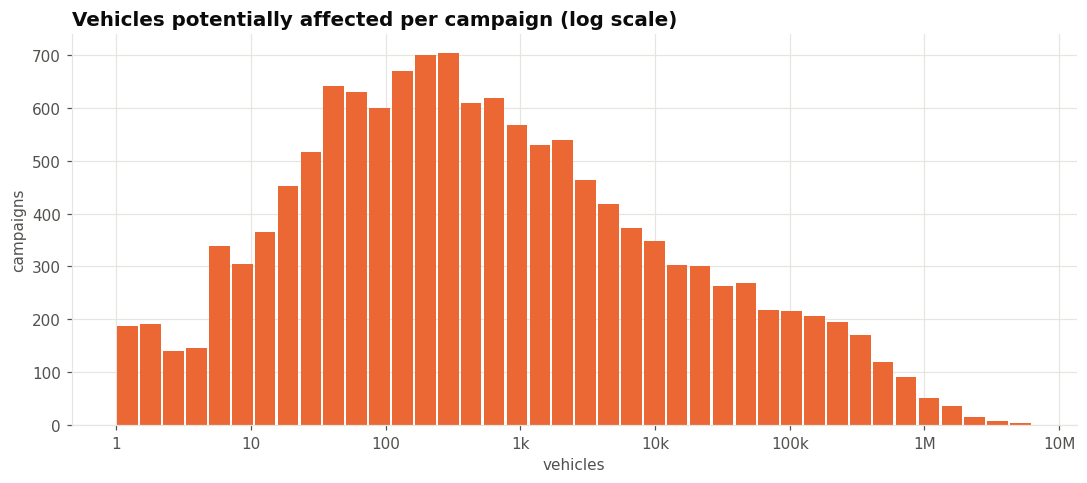

In [12]:
hbar(campaigns["COMPONENT"].value_counts().head(TOP_N), f"Top {TOP_N} components by recall campaigns",
     "campaigns", color=ORANGE, subtitle="A campaign covering several components is counted under its first listed one")

if "INFLUENCED_BY" in campaigns:
    by = campaigns.assign(year=campaigns["RCDATE"].dt.year)
    by["source"] = by["INFLUENCED_BY"].astype(str).where(by["INFLUENCED_BY"].isin(["MFR", "ODI"]), "OTHER")
    t = by.groupby(["year", "source"]).size().unstack(fill_value=0)
    fig, ax = plt.subplots()
    for i, col in enumerate([x for x in ["MFR", "ODI", "OTHER"] if x in t]):
        ax.plot(t.index, t[col], color=PALETTE[i], marker="o", markersize=4, label=col)
    ax.legend(title="initiated by")
    finish(ax, "Recall campaigns per year by who initiated them", "year", "campaigns",
           subtitle="MFR = manufacturer, ODI = NHTSA's Office of Defects Investigation")

pot = campaigns["POTAFF"].dropna()
pot = pot[pot > 0]
fig, ax = plt.subplots()
ax.hist(np.log10(pot), bins=40, color=ORANGE, rwidth=0.9)
ax.set_xticks(range(0, 8), ["1", "10", "100", "1k", "10k", "100k", "1M", "10M"])
finish(ax, "Vehicles potentially affected per campaign (log scale)", "vehicles", "campaigns")

---
## 4. Complaints ↔ recalls: how do they relate?

These are **associations**, not causes. Popular vehicles get both more complaints and more recalls simply because
more of them are on the road.

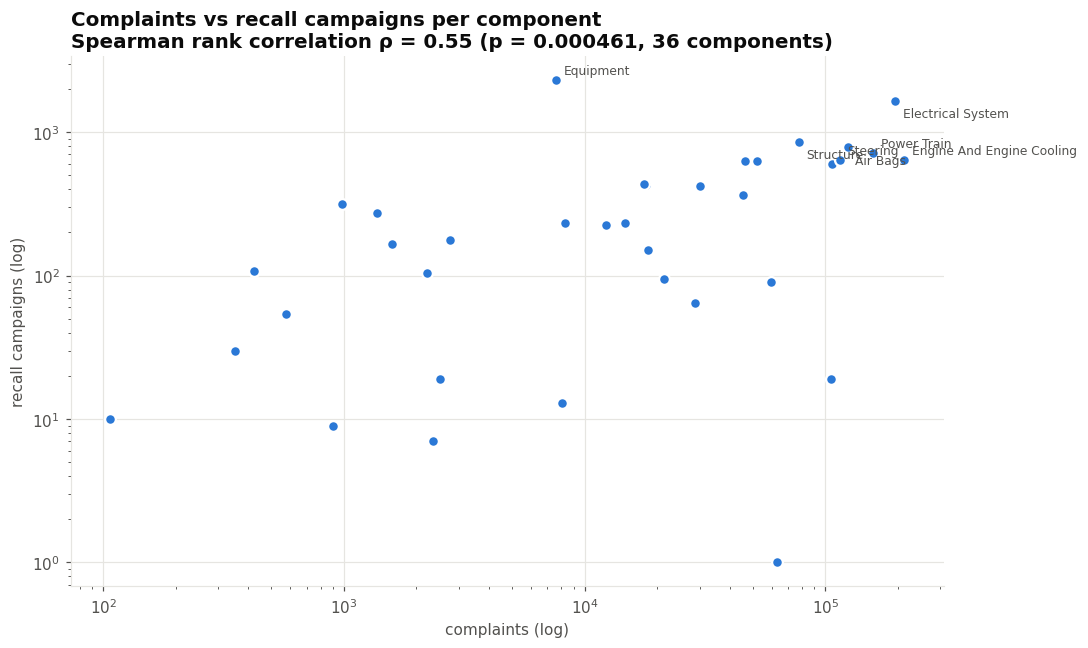

In [13]:
# 4.1 Do components that get many complaints also get many recalls?
comp = pd.DataFrame({"complaints": c["COMPONENT"].value_counts(),
                     "campaigns": campaigns["COMPONENT"].value_counts()}).fillna(0)
comp = comp[(comp["complaints"] > 0) & (comp["campaigns"] > 0)]
rho, p = spearmanr(comp["complaints"], comp["campaigns"])
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(comp["complaints"], comp["campaigns"], s=50, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
label_these = comp.nlargest(5, "complaints").index.union(comp.nlargest(3, "campaigns").index)
for k, (name, row) in enumerate(comp.loc[label_these].sort_values("complaints").iterrows()):
    ax.annotate(name.title(), (row["complaints"], row["campaigns"]), fontsize=8, color=MUTED,
                xytext=(5, 4 if k % 2 == 0 else -11), textcoords="offset points")   # alternate to limit overlap
ax.set_xscale("log"); ax.set_yscale("log")
finish(ax, "Complaints vs recall campaigns per component", "complaints (log)", "recall campaigns (log)",
       subtitle=f"Spearman rank correlation ρ = {rho:.2f} (p = {p:.3g}, {len(comp)} components)")

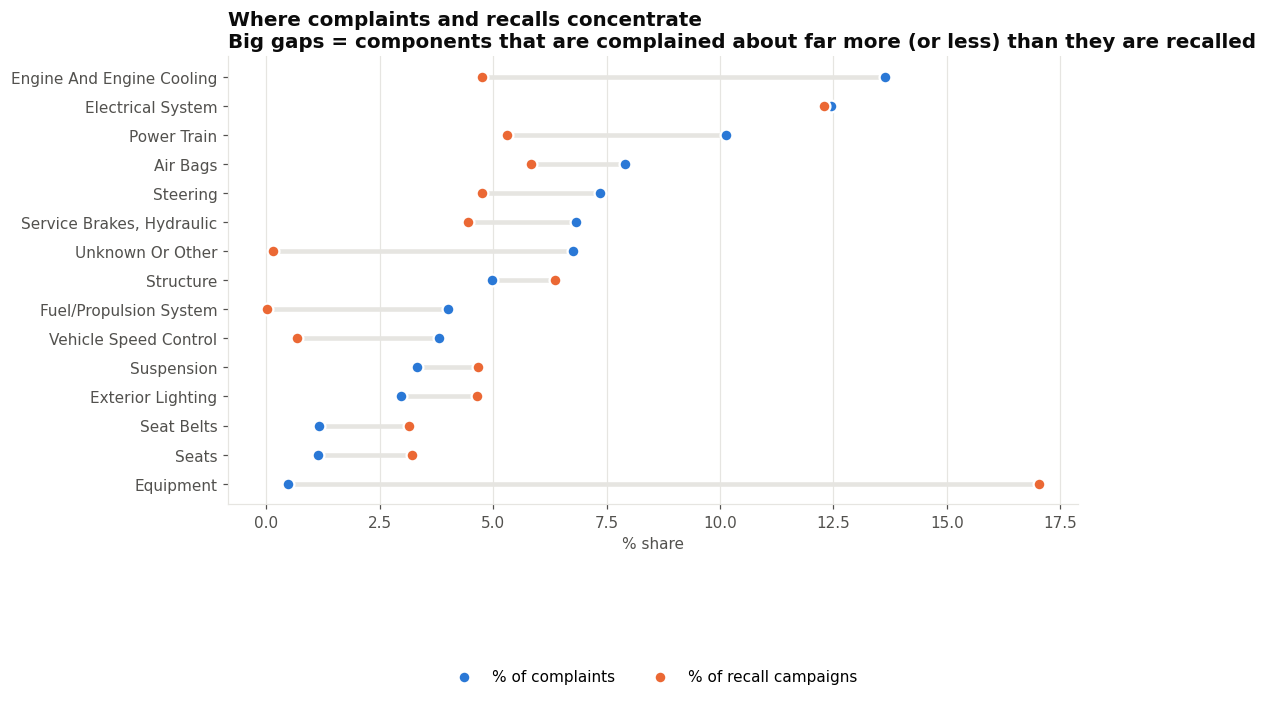

In [14]:
# 4.2 Share of complaints vs share of recalls per component (dumbbell)
share = pd.DataFrame({"% of complaints": 100 * c["COMPONENT"].value_counts(normalize=True),
                      "% of recall campaigns": 100 * campaigns["COMPONENT"].value_counts(normalize=True)}).fillna(0)
share = share.loc[share.max(axis=1).nlargest(TOP_N + 3).index].sort_values("% of complaints")
fig, ax = plt.subplots(figsize=(10, 0.36 * len(share) + 1.5))
y = np.arange(len(share))
ax.hlines(y, share.min(axis=1), share.max(axis=1), color=GRID, linewidth=3, zorder=1)
ax.scatter(share["% of complaints"], y, color=BLUE, s=60, zorder=3, edgecolor="white", linewidth=1.5, label="% of complaints")
ax.scatter(share["% of recall campaigns"], y, color=ORANGE, s=60, zorder=3, edgecolor="white", linewidth=1.5,
           label="% of recall campaigns")
ax.set_yticks(y, share.index.str.title()); ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12 - 1.5 / (0.36 * len(share) + 1.5)), ncol=2)
finish(ax, "Where complaints and recalls concentrate", "% share",
       subtitle="Big gaps = components that are complained about far more (or less) than they are recalled")

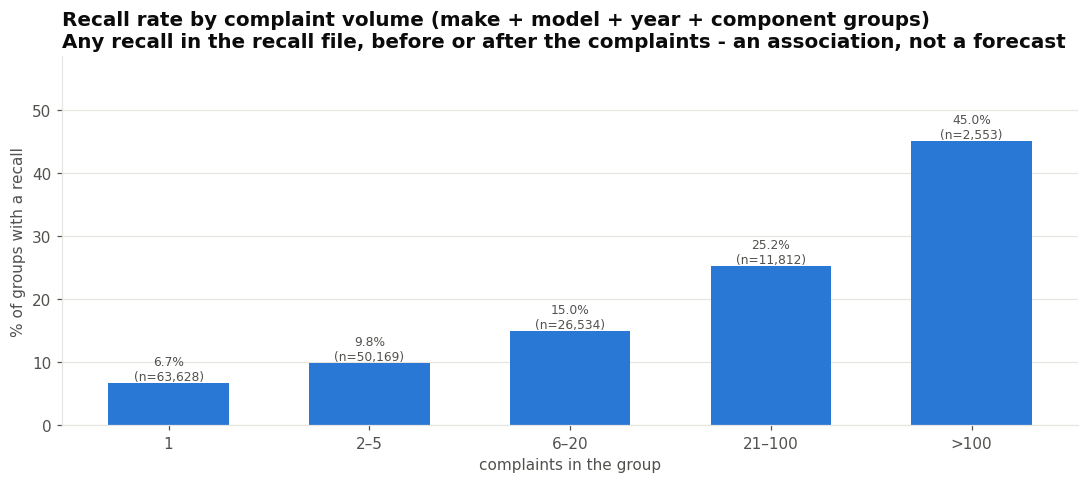

In [15]:
# 4.3 Are vehicle/component groups with more complaints more likely to have a recall?
grp = c.groupby("MMYC").size().rename("complaints").to_frame()
grp["recalled"] = grp.index.isin(set(r["MMYC"])).astype(int)
bins = [0, 1, 5, 20, 100, np.inf]; labels = ["1", "2–5", "6–20", "21–100", ">100"]
grp["bucket"] = pd.cut(grp["complaints"], bins=bins, labels=labels)
rate = grp.groupby("bucket", observed=True).agg(groups=("recalled", "size"), recall_rate=("recalled", "mean"))
fig, ax = plt.subplots()
ax.bar(rate.index.astype(str), 100 * rate["recall_rate"], color=BLUE, width=0.6)
for i, (v, n) in enumerate(zip(rate["recall_rate"], rate["groups"])):
    ax.text(i, 100 * v, f"{100 * v:.1f}%\n(n={n:,})", ha="center", va="bottom", fontsize=8, color=MUTED)
ax.set_ylim(0, 100 * rate["recall_rate"].max() * 1.3); ax.grid(axis="x", visible=False)
finish(ax, "Recall rate by complaint volume (make + model + year + component groups)",
       "complaints in the group", "% of groups with a recall",
       subtitle="Any recall in the recall file, before or after the complaints - an association, not a forecast")

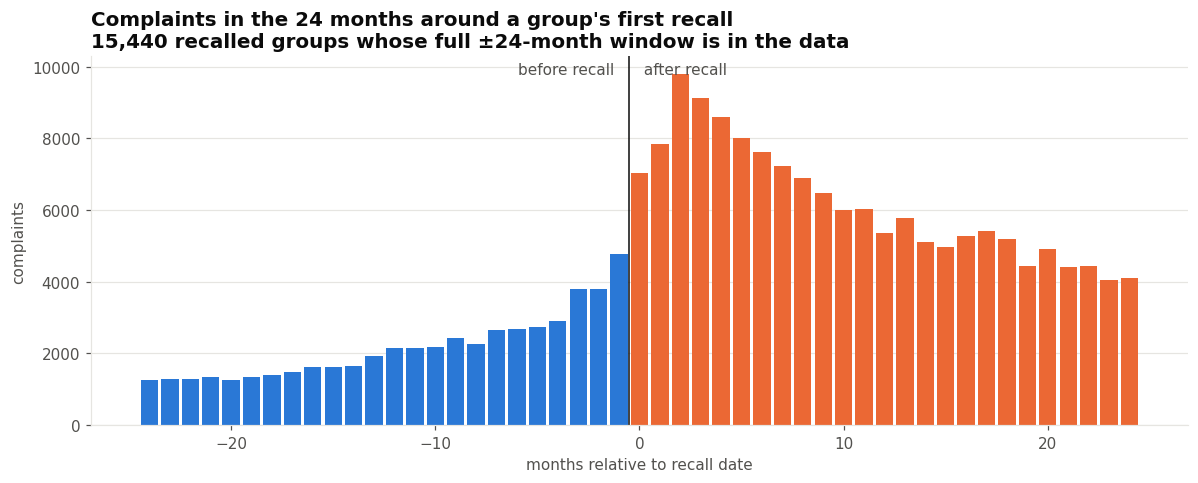

In [16]:
# 4.4 Complaint volume around the recall date ("event study")
first_recall = r.groupby("MMYC")["RCDATE"].min()
cm = c[["MMYC", "DATEA"]].join(first_recall.rename("recall_date"), on="MMYC", how="inner")
lo, hi = c["DATEA"].min() + pd.Timedelta(days=730), c["DATEA"].max() - pd.Timedelta(days=730)
cm = cm[(cm["recall_date"] >= lo) & (cm["recall_date"] <= hi)]          # full ±24-month window observable
cm["month"] = np.floor((cm["DATEA"] - cm["recall_date"]).dt.days / 30.44).astype(int)
ev = cm[cm["month"].between(-24, 24)].groupby("month").size()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(ev.index, ev.values, color=[BLUE if m < 0 else ORANGE for m in ev.index], width=0.85)
ax.axvline(-0.5, color=TEXT, linewidth=1)
ax.text(-1, ev.max(), "before recall ", ha="right", color=MUTED); ax.text(0, ev.max(), " after recall", color=MUTED)
ax.grid(axis="x", visible=False)
finish(ax, "Complaints in the 24 months around a group's first recall", "months relative to recall date",
       "complaints", subtitle=f"{cm['MMYC'].nunique():,} recalled groups whose full ±24-month window is in the data")

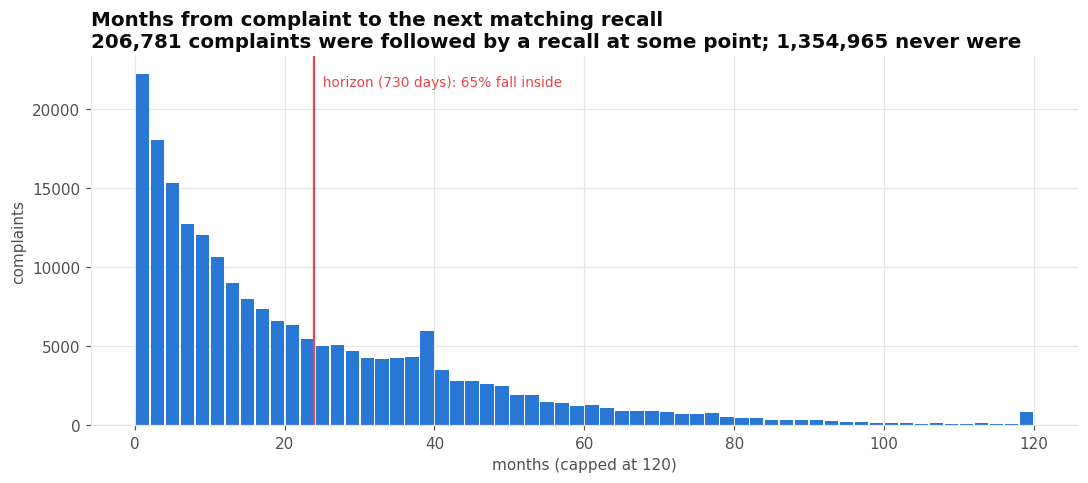

In [17]:
# 4.5 For complaints that were followed by a recall: how long until it came?
from recall_pipeline.labeling import recall_lookup
lk = recall_lookup(c.assign(GROUP_KEY=c["MMYC"]), "DATEA", r, KEYS)
wait = ((lk["next_recall"] - c["DATEA"]).dt.days / 30.44).dropna()
fig, ax = plt.subplots()
ax.hist(wait.clip(upper=120), bins=60, color=BLUE, rwidth=0.9)
ax.axvline(HORIZON_DAYS / 30.44, color=RED, linewidth=1.5)
ax.text(HORIZON_DAYS / 30.44, ax.get_ylim()[1] * 0.92, f"  horizon ({HORIZON_DAYS} days): "
        f"{100 * (wait <= HORIZON_DAYS / 30.44).mean():.0f}% fall inside", color=RED, fontsize=9)
finish(ax, "Months from complaint to the next matching recall", "months (capped at 120)", "complaints",
       subtitle=f"{len(wait):,} complaints were followed by a recall at some point; "
                f"{len(c) - len(wait):,} never were")

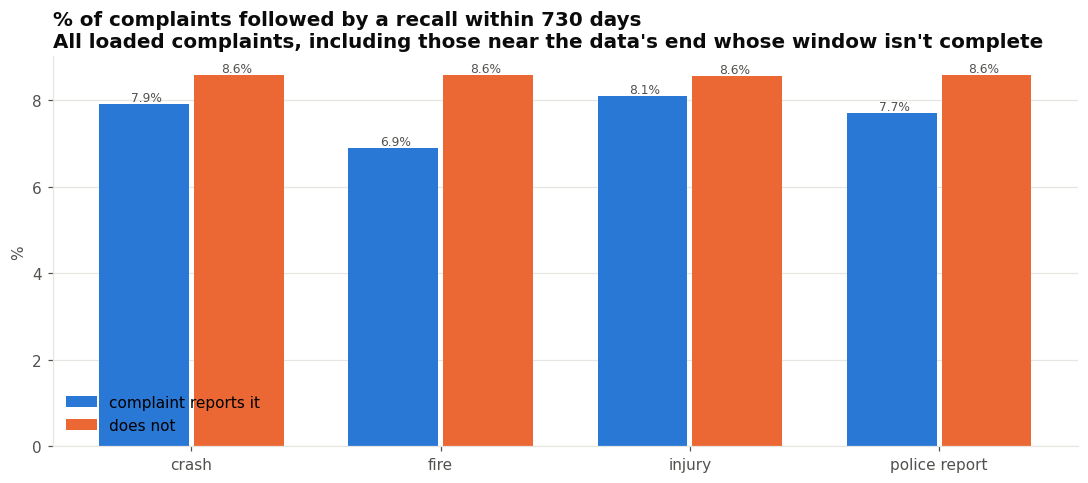

In [18]:
# 4.6 Are serious complaints more often followed by a recall within the horizon?
y = ((lk["next_recall"] - c["DATEA"]).dt.days <= HORIZON_DAYS).astype(int)
rows = []
for col, label in [("CRASH_flag", "crash"), ("FIRE_flag", "fire"), ("injury_flag", "injury"), ("POLICE_RPT_YN_flag", "police report")]:
    rows.append({"flag": label, "yes": 100 * y[c[col] == 1].mean(), "no": 100 * y[c[col] == 0].mean()})
t = pd.DataFrame(rows).set_index("flag")
fig, ax = plt.subplots()
x = np.arange(len(t)); w = 0.36
ax.bar(x - w / 2 - 0.01, t["yes"], w, color=BLUE, label="complaint reports it")
ax.bar(x + w / 2 + 0.01, t["no"],  w, color=ORANGE, label="does not")
for i in range(len(t)):
    ax.text(i - w / 2, t["yes"].iloc[i], f"{t['yes'].iloc[i]:.1f}%", ha="center", va="bottom", fontsize=8, color=MUTED)
    ax.text(i + w / 2, t["no"].iloc[i], f"{t['no'].iloc[i]:.1f}%", ha="center", va="bottom", fontsize=8, color=MUTED)
ax.set_xticks(x, t.index); ax.legend(); ax.grid(axis="x", visible=False)
finish(ax, f"% of complaints followed by a recall within {HORIZON_DAYS} days", None, "%",
       subtitle="All loaded complaints, including those near the data's end whose window isn't complete")

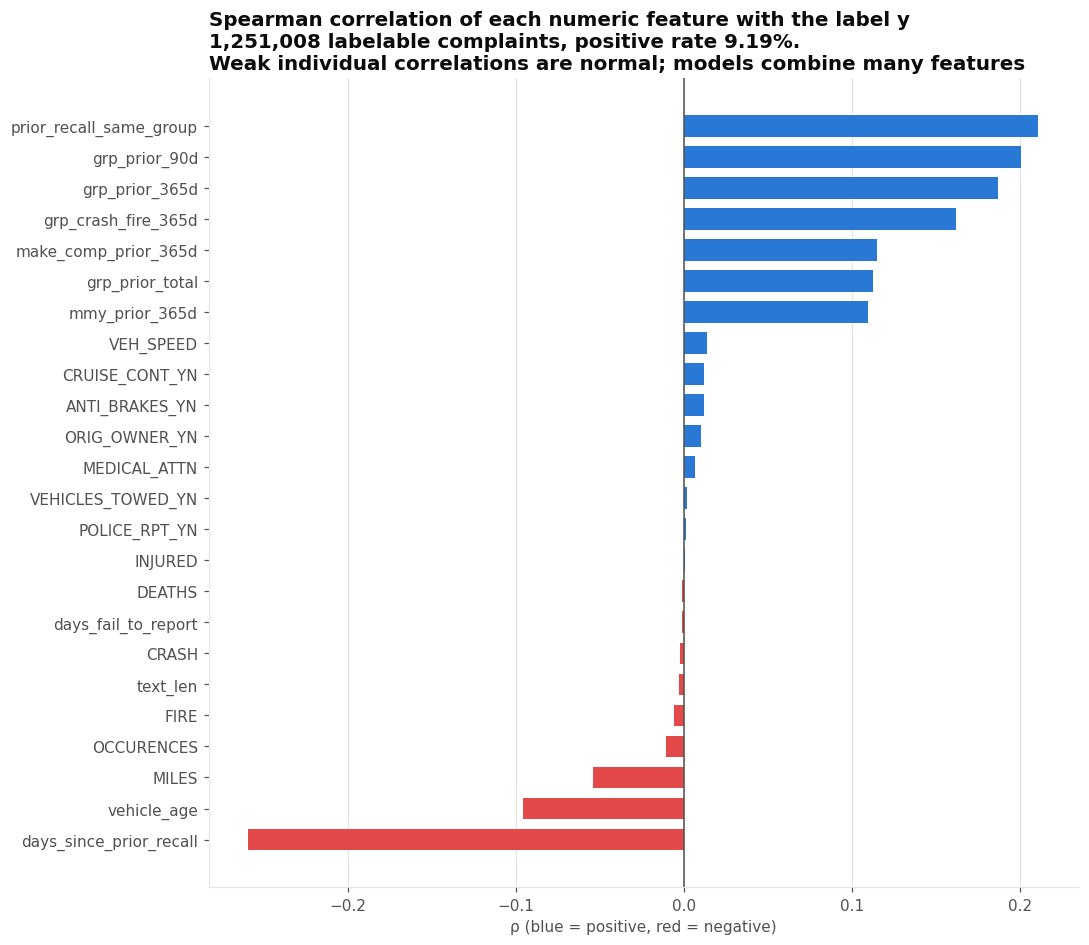

In [19]:
# 4.7 Which engineered model features move with the label? (rank correlation, labelable rows only)
from recall_pipeline.labeling import build_labels
from recall_pipeline.features import engineer, feature_columns
df = engineer(build_labels(c.drop(columns=["MMYC"]), r, cfg), cfg)
df = df[df["labelable"]]
num, _, _ = feature_columns(df, cfg)
corr = {f: spearmanr(df[f], df["y"], nan_policy="omit")[0] for f in num
        if df[f].nunique() > 1 and df[f].notna().mean() > 0.01}       # skip constant / almost-empty columns
corr = pd.Series(corr).dropna().sort_values()
fig, ax = plt.subplots(figsize=(10, 0.3 * len(corr) + 1.5))
ax.barh(corr.index, corr.values, color=[BLUE if v > 0 else RED for v in corr.values], height=0.7)
ax.axvline(0, color=MUTED, linewidth=1); ax.grid(axis="y", visible=False)
finish(ax, "Spearman correlation of each numeric feature with the label y", "ρ (blue = positive, red = negative)",
       subtitle=f"{len(df):,} labelable complaints, positive rate {100 * df['y'].mean():.2f}%.\n"
                "Weak individual correlations are normal; models combine many features")

---
### Interpreting the charts
* **Section 2** describes failures. Raw counts track how many vehicles are on the road, so compare *shares* and
  *rates* (heatmap, severity panels) rather than counts when comparing makes.
* **4.1–4.3** show complaints and recalls are associated across components and vehicle groups. Part of that is
  exposure (more vehicles → more of both).
* **4.4** shows the timing: complaints building *before* the recall (the signal a model can use) and the jump
  *after* it (owners reacting to the recall, which is why the pipeline only uses complaints *before* a recall as
  evidence).
* **4.5** shows how much of the signal the 2-year horizon captures; try `HORIZON_DAYS = 365` or `1095`.
* **4.7** previews which model features carry signal on their own.